# Ekman transport, MSE and Ekman advection maps

Maps of the pentad composites (`ekman_mse.jl`, written by `save_composite`), averaged over a period chosen here.

Two libraries, loaded with Revise `includet`, so edits to them take effect here without restarting the kernel:
- `composites.jl`: reading composites and computing the fields (`ekman_fields`), in sections: general (any composite file), pentad climatology, BSISO phases.
- `maps.jl`: plotting: settings, general maps (`panel`, `arrows`, `plot_panels`), and the figures of `ekman_fields` (`fig_transport_mse`, `fig_adv`, `fig_flux`), shared by `ekman_plots.ipynb` and `bsiso_plots.ipynb`.

Platform display settings (resolution, fonts, SVG) are in the first cell; the period and region in **Data**; color limits and axes in each figure's call.

Kernel: the Jupyter kernel "Julia" (IJulia; juliaup default Julia, project `plot/`). It shows each figure at the end of the cell that makes it, so there is no `display`; adjust a figure in that cell. The Julia extension's own "Julia release channel" kernel does not show figures automatically.

In [10]:
using Revise, Dates
includet("composites.jl") # reading composites, computing fields
includet("maps.jl")       # plotting

# display settings, which depend on the platform; change them here if figures look wrong or hang
plot_defaults!(; dpi=200) # inline figure size on screen (inches x dpi); fonts=[...]: font list
PythonPlot.svg(false)     # true: inline SVG, which scales to the pane (maps are rasterized, so it stays small)

false

## Data
`ekman_fields(file, first_day, last_day; n, lonlim, latlim, Ro_rad)`: the mean over the `n` pentads best aligned with the dates (year ignored; 365-day calendar; `n=nothing`: all pentads touching the dates), weighted by daily counts, in the region `lonlim`, `latlim` (only that region is read). It is `ekman_fields(read_period(file, first_day, last_day; n, lonlim, latlim); Ro_rad)`: read, then compute. Another period is one line (see the last section). `f` is a NamedTuple; `keys(f)` lists the fields, e.g. `f.adv_o`, `f.taux`; `f.dimval` the pentads. Gradients are NaN on the region's edge rows and columns.

The composites use the uncurtailed Ekman transport. `ekman_fields` multiplies M by `r = curtail(lat, Ro_rad)` (`f.r`), a function of latitude only, so `Ro_rad` can be changed here without recompositing. It matters only within ~5° of the equator.

In [2]:
file = "../ekman_pentad_clim_2012-2020.nc"
lonlim, latlim = (40, 110), (0, 25) # degrees: Indian Ocean; only this region is read
Ro_rad = 250e3 # m, curtail M by r = 1 - exp(-y^2/Ro_rad^2) near the equator (plotting only)
figtitle(f) = "$(basename(file)): $(period_label(f.dimval)) (Ro_rad = $(Ro_rad/1e3) km)"

# May: the 6 pentads best aligned with May (year ignored): pentads 25:30, May 1-30
f = ekman_fields(file, Date(2001, 5, 1), Date(2001, 5, 31); n=6, lonlim, latlim, Ro_rad)
f.dimval, size(f.Mx), keys(f)

(Int32[25, 26, 27, 28, 29, 30], (281, 101), (:lon, :lat, :taux, :tauy, :Mx, :My, :m_a, :m_o, :dmodx, :dmody, :dmadx, :dmady, :advT_o, :advT_a, :adv_o, :adv_a, :sdiv_o, :sdiv_a, :flux_o, :flux_a, :r, :land, :dim, :dimval))

## Ekman transport, surface-air MSE and ocean-surface enthalpy
The figure functions (`maps.jl`) take the fields `f`, a `title`, color limits, and keywords for `plot_panels` (`ylim`, `xlim`, `ncols`, `figsize`), and return `(fig, axs, pcs, cbs, qs)`: axes `axs[row, col]` (from 0), and the meshes, colorbars and arrows of panel k, `pcs[k]`, `cbs[k]`, `qs[k]`. Wind stress arrows: `tau=arrows(f.taux, f.tauy; every, scale, key, keylabel)`, every `every`-th grid point, `scale` N m$^{-2}$ per inch of arrow, the same on all panels. For other panels, call `plot_panels(f, [panel(x, title, units; cmap, vec, vmin, vmax), ...])` directly.

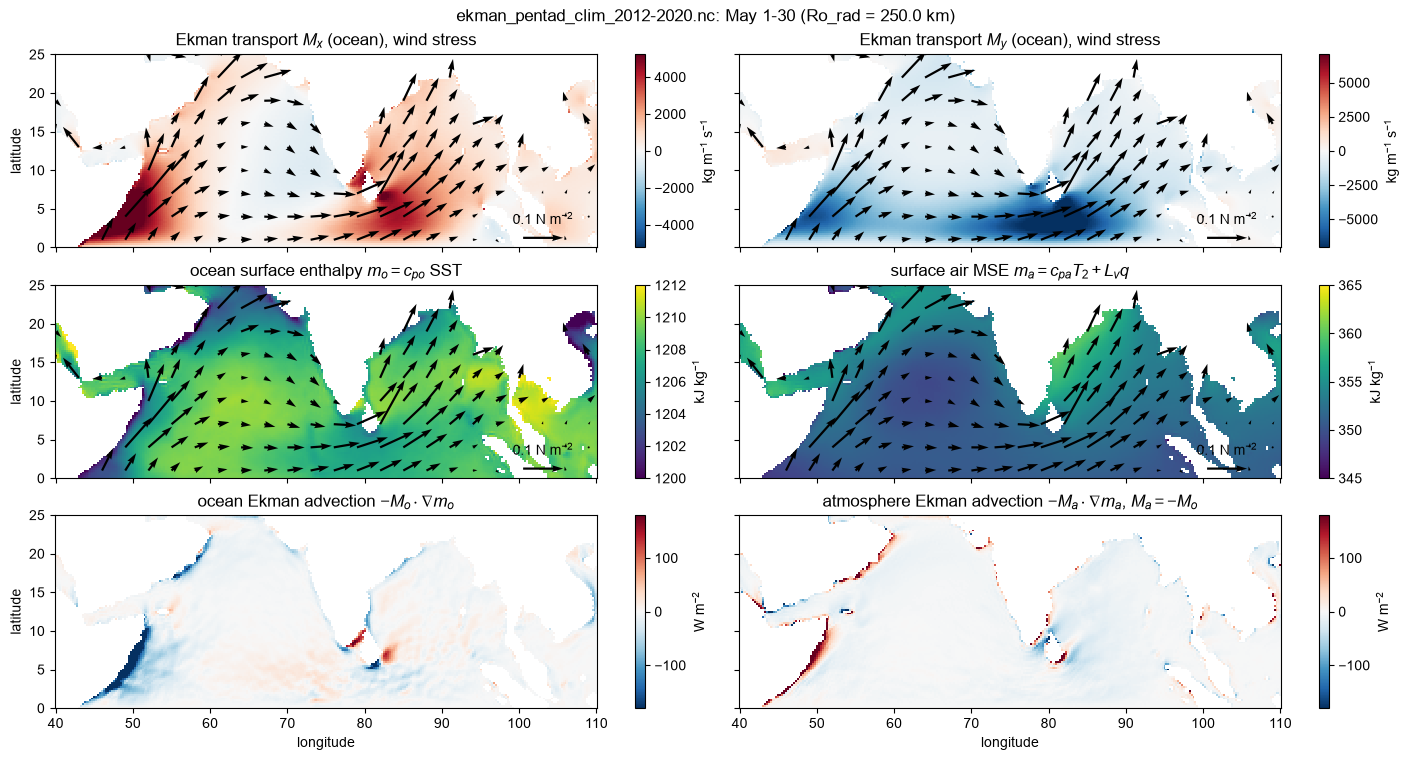

In [3]:
fig1, axs1, pcs1, cbs1, qs1 = fig_transport_mse(f; title=figtitle(f), mo_lims=(1200, 1212), ma_lims=(345, 365), advlim=180, ylim=latlim);
# adjust here, e.g. cbs1[3].set_ticks(1200:3:1212); axs1[0, 0].set_xlim(50, 100); qs1[1].set_color("w")
# fig1.savefig("ekman_V_ma_mo_$(period_tag(f.dimval)).png"; bbox_inches="tight")

Atmosphere and ocean (moist) enthalpy color ranges are both 20 kJ/kg. The atmosphere has a gradient in the Bay of Bengal, but not much in the Arabian Sea. Theres a maximum (SST) in the central AS. Atmosphere and Ocean have nearly opposite MSE gradients around 20 N in the Arabian Sea. Both gradients result in cool advection, because of the southward ocean and northward atmosphere Ekman transport.

In [4]:
# Adjust a figure in the cell that makes it, after the figure call (axes axs1[row, col] from 0,
# colorbars cbs1[k], arrows qs1[k] of panel k). The figure is drawn when that cell ends.

## Ocean and atmosphere Ekman advection and their sum
Columns: temperature (SST, $T_2$; mass-weighted, K kg m$^{-2}$ s$^{-1}$, ±`Tlim`), and enthalpy (ocean $m_o$) and moist enthalpy (atmosphere $m_a$), W m$^{-2}$, ±`Hlim`. Rows: ocean, atmosphere, sum, difference.

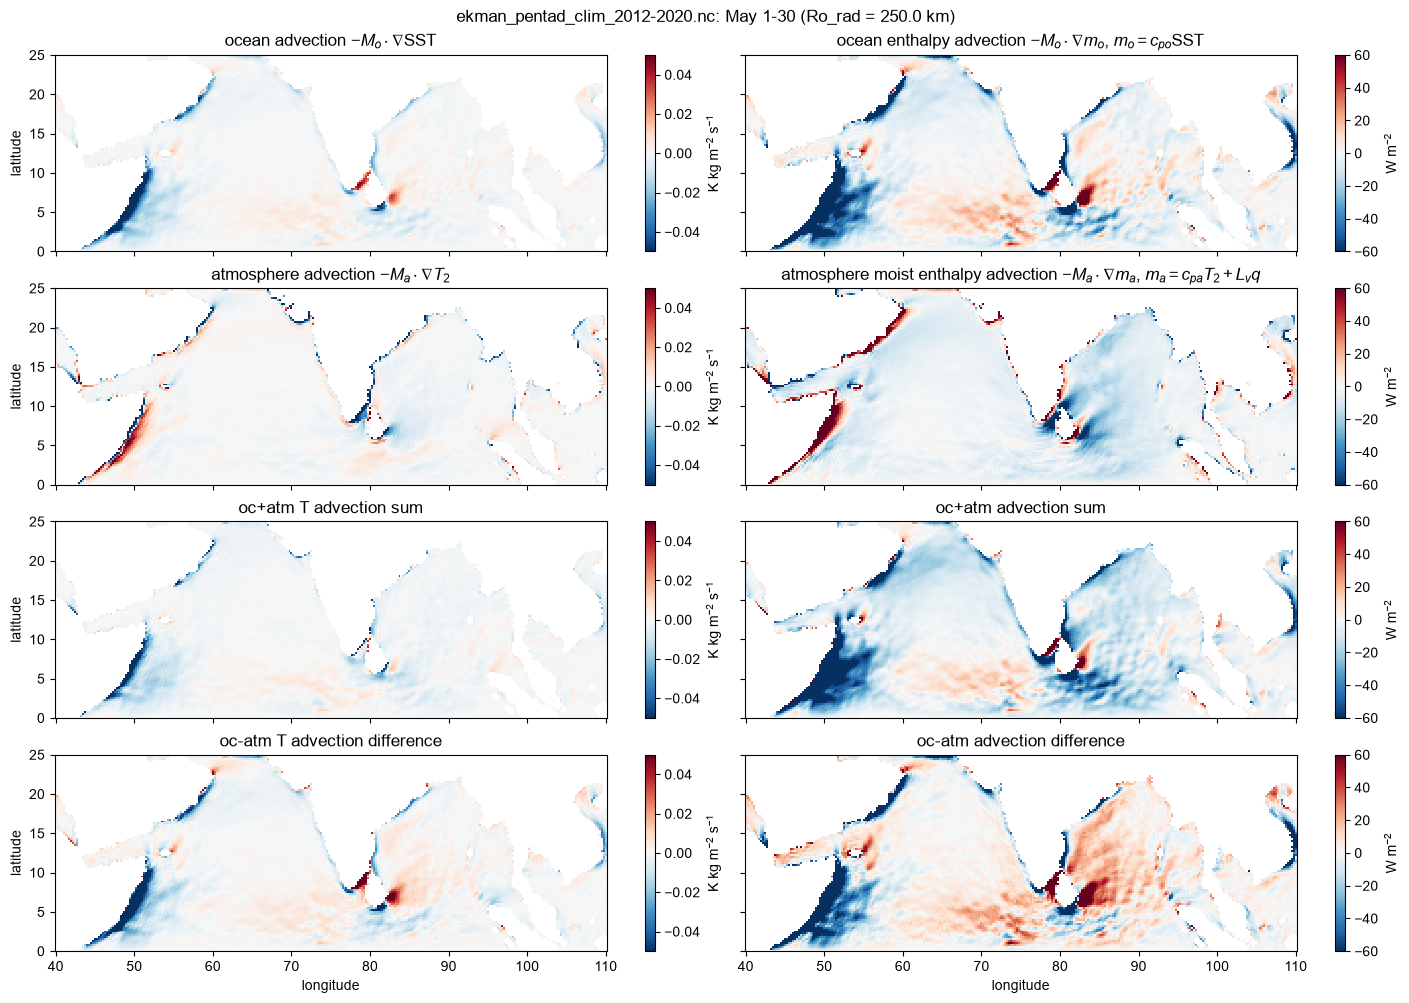

In [5]:
fig_adv1, axs_adv1, pcs_adv1, cbs_adv1, qs_adv1 = fig_adv(f; title=figtitle(f), Tlim=0.05, Hlim=60, ylim=latlim);
# fig_adv1.savefig("ekman_adv_sum_$(period_tag(f.dimval)).png"; bbox_inches="tight")

The ASTZ sum of Ekman advection is mostly cooling. It warms only where we might expect there to be an ISO atmospheric vortex (FNISO). The atmospheric cold advection of -10 W m$^2$ dominates everywhere in the open ocean. Ocean advection is more variable and takes both signs. It is notably positive in May along 5 N, 60-80 E.

The two signs in the difference plot (lowest right) demonstrate two regimes: 

(positive, red) Ekman advection warms ocean relative to atmosphere. 
This reflects atmospheric cooling advection by baroclinic frictional wind, which flows down pressure gradients from cool T to warmer T. 
This is expected for SST driving the surface wind response in the atmosphere.

(negative, blue) Ekman advection cools ocean relative to atmosphere. 
This reflects ocean cooling by advection from cool regions of SST, such as created by Ekman divergence and upwelling. 
This is expected for wind stress driving the surface temperature response in the ocean.

The monsoon influence the Ekman transport in the ocean. Both the wind and the SST gradient shift northward from May to June. In May, warming advection along 5N advects southward from the AS warm pool under westward winds. In June, the warming advection shifts northward, with a southeastward Ekman flux under the northeastward Findlater jet.

## Another period
Read → fields → figure, with the same figure functions.

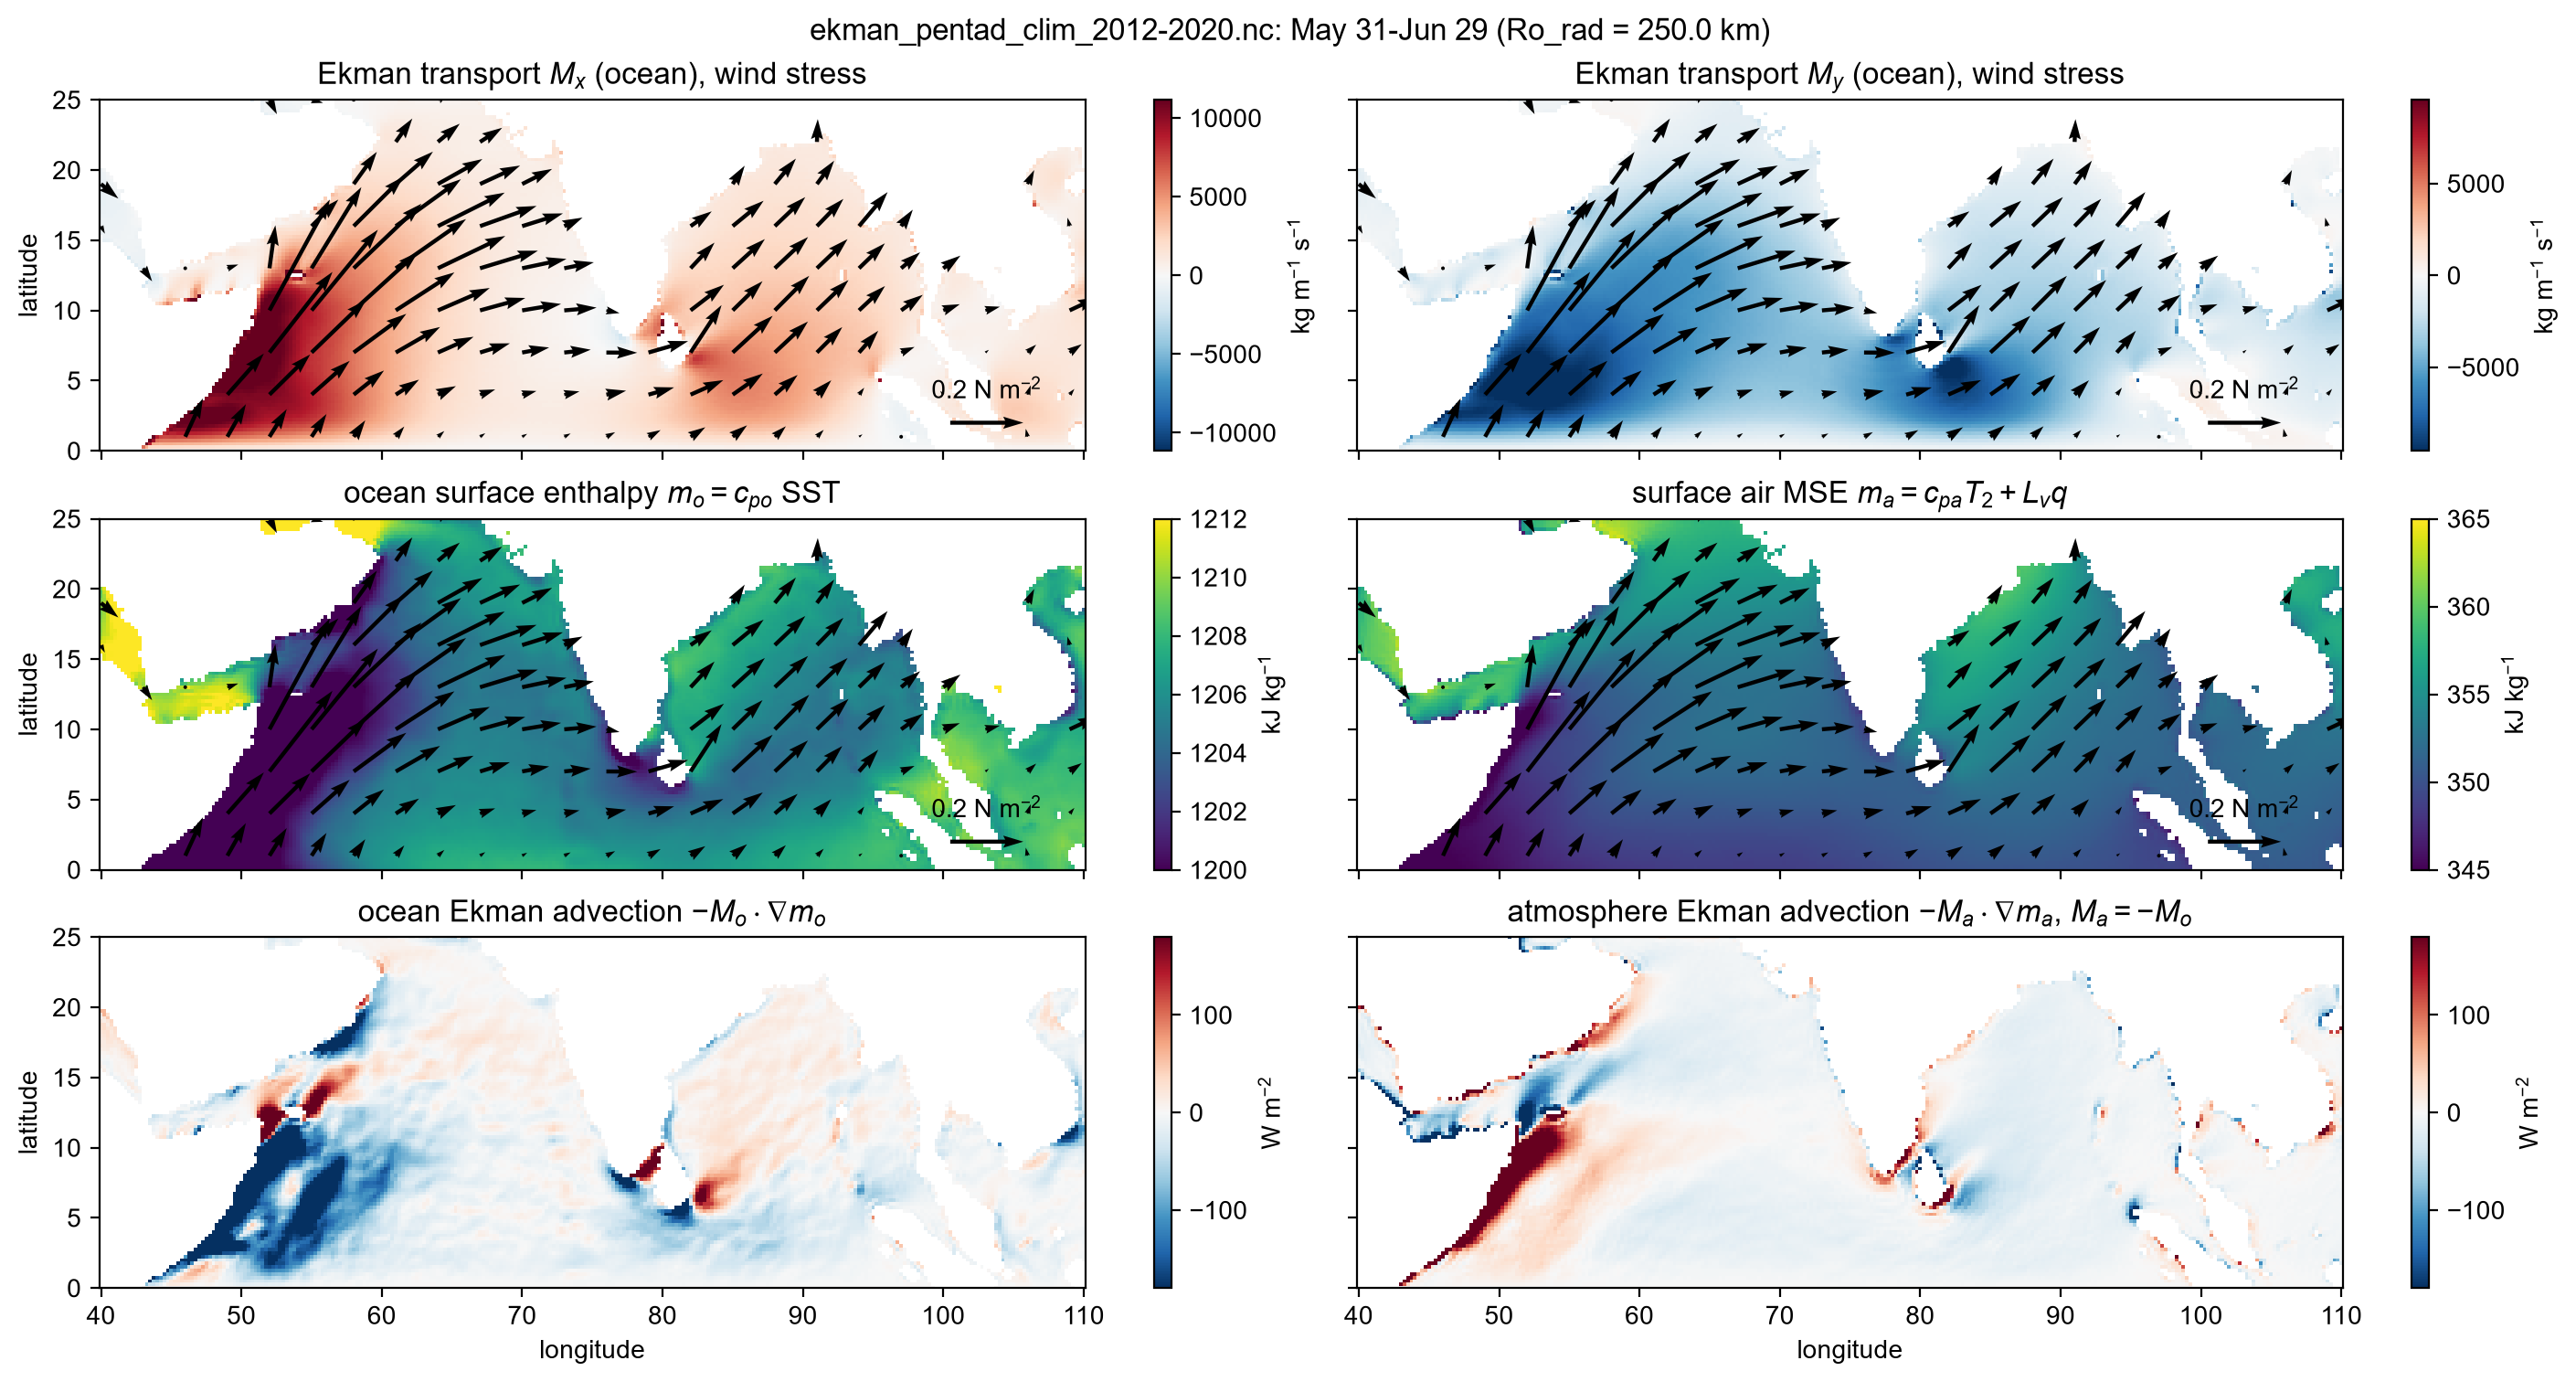

In [17]:
# any other period: read -> fields -> figure, e.g. June (pentads 31:36, May 31-Jun 29)
f_jun = ekman_fields(file, Date(2001, 6, 1), Date(2001, 6, 30); n=6, lonlim, latlim, Ro_rad)
f_mayjun = ekman_fields(file, Date(2001, 5, 20), Date(2001, 6, 10); n=4, lonlim, latlim, Ro_rad)
fig_jun, axs_jun = fig_transport_mse(f_jun; title=figtitle(f_jun), ylim=latlim,
    tau=arrows(f_jun.taux, f_jun.tauy; scale=0.5, key=0.2, keylabel=raw"0.2 N m$^{-2}$"));

## May to June: shift of ocean Ekman advection
Ocean Ekman advection $-M_o \cdot \nabla m_o$ (colors, ±`advlim_o`), SST (contours, °C, `sst_levels`) and wind stress (arrows, the same scale in both panels), May (`f`) and June (`f_jun`, from the cell above). `contours(x; levels, colors, ...)` and `arrows(...)` are drawn on a `panel` with `con=` and `vec=`.

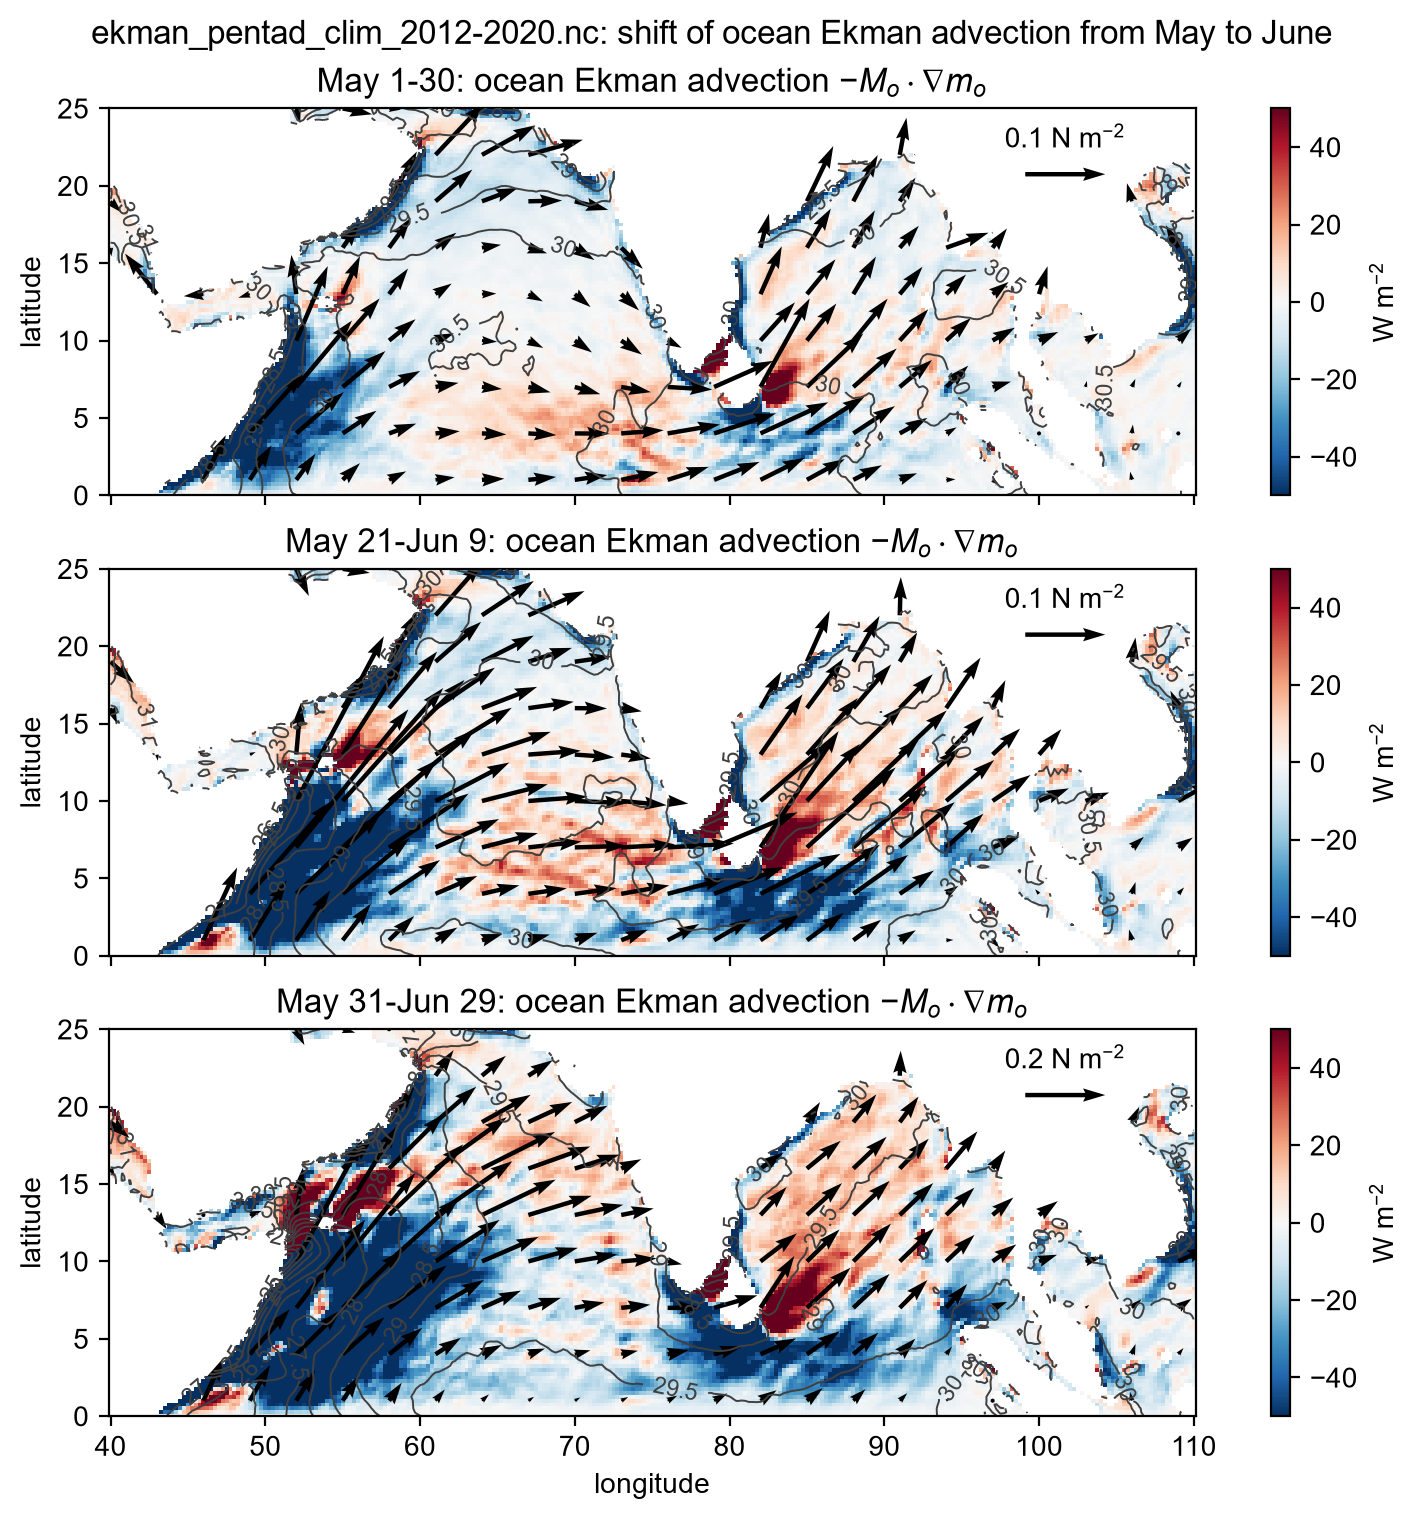

In [18]:
# May to June: each panel colors ocean Ekman advection, contours SST (°C), quivers wind stress
may, mayjun, jun = f, f_mayjun, f_jun
ne = (0.88, 0.83) # wind stress key position (axes fraction): northeast corner, over land
fig_shift, axs_shift, pcs_shift, cbs_shift, qs_shift, cs_shift = fig_ocean_advection([may, mayjun, jun], period_label.([may.dimval, mayjun.dimval, jun.dimval]);
    advlim = 50,                                              # W m^-2
    sst = [sst_contours(may; levels=24:0.5:31),
           sst_contours(mayjun; levels=24:0.5:31),
           sst_contours(jun; levels=24:0.5:31)],
    tau = [stress_arrows(may; scale=0.25, key=0.1, keypos=ne),  # May arrows twice as long as June's
           stress_arrows(mayjun; scale=0.25, key=0.1, keypos=ne),
           stress_arrows(jun; scale=0.5,  key=0.2, keypos=ne)],
    ncols=1, ylim=latlim, suptitle="$(basename(file)): shift of ocean Ekman advection from May to June");
# fig_shift.savefig("ekman_adv_o_$(period_tag(may.dimval))_$(period_tag(jun.dimval)).png"; bbox_inches="tight")

June (monsoon season) wind drive frictional Ekman warm advection in the ocean in the northern Indian Ocean, both in the western Bay of Benga and the northern Arabian Sea (AS). The wind shifts from 5 N to 15 N in the central AS.